# 01 · Análise exploratória (EDA)
**Tech Challenge – Fase 2 · Grupo 01 · POSTECH Data Analytics**

Objetivo do projeto: prever se um solicitante de cartão de crédito será **bom** ou **mau pagador** a partir dos dados do cadastro.
Neste notebook conhecemos os dados: tamanho, nulos, variável alvo, distribuições, outliers, correlações e diferenças entre bons e maus pagadores.
Cada gráfico vem acompanhado de uma leitura em linguagem simples.

In [1]:
RANDOM_STATE = 42   # semente fixa

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
RAW = "../data/raw/"

## 1. Os dados
São duas tabelas: **application_record** (cadastro do solicitante) e **credit_record** (histórico mensal de pagamento de cada cliente). O dicionário de variáveis está no `README.md`.

In [2]:
app = pd.read_csv(RAW + "application_record.csv")
cred = pd.read_csv(RAW + "credit_record.csv")
print("application_record:", app.shape, "| IDs únicos:", app.ID.nunique())
print("credit_record     :", cred.shape, "| IDs únicos:", cred.ID.nunique())
print("IDs presentes nas duas tabelas:", len(set(app.ID) & set(cred.ID)))
display(app.head(3))
display(cred.head(3))

application_record: (438557, 18) | IDs únicos: 438510
credit_record     : (1048575, 3) | IDs únicos: 45985
IDs presentes nas duas tabelas: 36457


,ID,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS
0,5008804,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
1,5008805,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
2,5008806,M,Y,Y,0,112500.0,Working,Secondary / secondary special,Married,House / apartment,-21474,-1134,1,0,0,0,Security staff,2.0


,ID,MONTHS_BALANCE,STATUS
0,5001711,0,X
1,5001711,-1,0
2,5001711,-2,0


**Leitura:** o cadastro tem 438 mil linhas, mas o histórico de pagamento existe só para cerca de 46 mil clientes, e apenas **36.457 aparecem nas duas tabelas**.
Só esses podem ser usados, porque só neles sabemos se a pessoa pagou em dia. Os demais não têm "resposta" para o modelo aprender.

## 2. Valores nulos e duplicados

In [3]:
nulos = app.isna().sum().to_frame("nulos"); nulos["% da base"] = (nulos["nulos"] / len(app) * 100).round(1)
display(nulos[nulos.nulos > 0])
print("Nulos em credit_record:", int(cred.isna().sum().sum()))
print("IDs duplicados no cadastro:", int(app.ID.duplicated().sum()))
print("Valores distintos de FLAG_MOBIL:", app.FLAG_MOBIL.unique())
print("Linhas com DAYS_EMPLOYED = 365243 (código de 'sem emprego'):", f"{(app.DAYS_EMPLOYED == 365243).mean():.1%}")

Nulos em credit_record: 0
IDs duplicados no cadastro: 47
Valores distintos de FLAG_MOBIL: [1]
Linhas com DAYS_EMPLOYED = 365243 (código de 'sem emprego'): 17.2%


,nulos,% da base
OCCUPATION_TYPE,134203,30.6


**Leitura:**
- O único campo com nulos é **OCCUPATION_TYPE (30,6%)**. Não é aleatório: está muito ligado a aposentados/desempregados, então "não informado" também é uma informação.
- Há 47 IDs repetidos no cadastro (removidos depois).
- `FLAG_MOBIL` vale sempre 1: não ajuda a separar ninguém e será descartada.
- O valor **365243** em `DAYS_EMPLOYED` não é um tempo real de emprego: é um código para quem não trabalha (aposentados, desempregados) e será tratado à parte.

## 3. Variável alvo: quem é "mau pagador"?
Não existe uma coluna pronta de bom/mau. Ela é **construída** a partir de `STATUS` (atraso em cada mês):
`0` = 1–29 dias, `1` = 30–59, `2` = 60–89, `3` = 90–119, `4` = 120–149, `5` = 150+ dias; `C` = quitado; `X` = sem empréstimo no mês.

,definição de mau pagador,maus,clientes,% maus
0,atraso de 30 dias ou mais,4291,36457,11.77
1,atraso de 60 dias ou mais,616,36457,1.69
2,atraso de 90 dias ou mais,302,36457,0.83


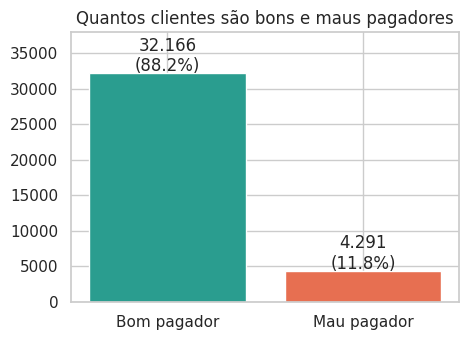

In [4]:
def build_target(cred, threshold=1):
    """1 = mau pagador (algum mês com atraso >= threshold), 0 = bom pagador."""
    bad_values = [str(s) for s in range(threshold, 6)]
    return cred["STATUS"].isin(bad_values).groupby(cred["ID"]).max().astype(int).rename("TARGET")

rows = []
for t, nome in [(1, "30 dias ou mais"), (2, "60 dias ou mais"), (3, "90 dias ou mais")]:
    tg = build_target(cred, t); tg = tg[tg.index.isin(app.ID)]       # só clientes com cadastro
    rows.append({"definição de mau pagador": f"atraso de {nome}", "maus": int(tg.sum()), "clientes": len(tg), "% maus": round(tg.mean() * 100, 2)})
display(pd.DataFrame(rows))

alvo = build_target(cred, 1)
base = app.drop_duplicates("ID").merge(alvo, left_on="ID", right_index=True)
fig, ax = plt.subplots(figsize=(5, 3.5))
cont = base.TARGET.map({0: "Bom pagador", 1: "Mau pagador"}).value_counts()
ax.bar(cont.index, cont.values, color=["#2a9d8f", "#e76f51"])
for i, v in enumerate(cont.values): ax.text(i, v + 300, f"{v:,}".replace(",", ".") + f"\n({v/len(base):.1%})", ha="center")
ax.set_title("Quantos clientes são bons e maus pagadores"); ax.set_ylim(0, cont.max() * 1.18)
plt.show()

**Leitura:** adotamos **mau pagador = pelo menos um mês com atraso de 30 dias ou mais**, o que dá **11,8%** de maus (4.291 clientes).
Com 60 dias restariam só 616 maus (1,7%) e com 90 dias, 302 (0,8%): poucos casos para o modelo aprender.
Os 30 dias mantêm volume suficiente.

**Balanceamento:** a base é **desbalanceada**: para cada mau pagador há cerca de 7,5 bons. Por isso, um modelo que aprovasse todo mundo acertaria 88%
e, ainda assim, seria inútil. Por isso vamos olhar métricas além da acurácia e usar pesos para as classes.

## 4. Distribuições das variáveis numéricas

                      mean       50%      min        max
AGE_YEARS             43.7      42.6     20.5       68.9
YEARS_EMPLOYED         7.2       5.5      0.0       43.0
AMT_INCOME_TOTAL  186685.7  157500.0  27000.0  1575000.0
CNT_CHILDREN           0.4       0.0      0.0       19.0
CNT_FAM_MEMBERS        2.2       2.0      1.0       20.0

Sem emprego/aposentados: 16.8% | Sem filhos: 69.1%


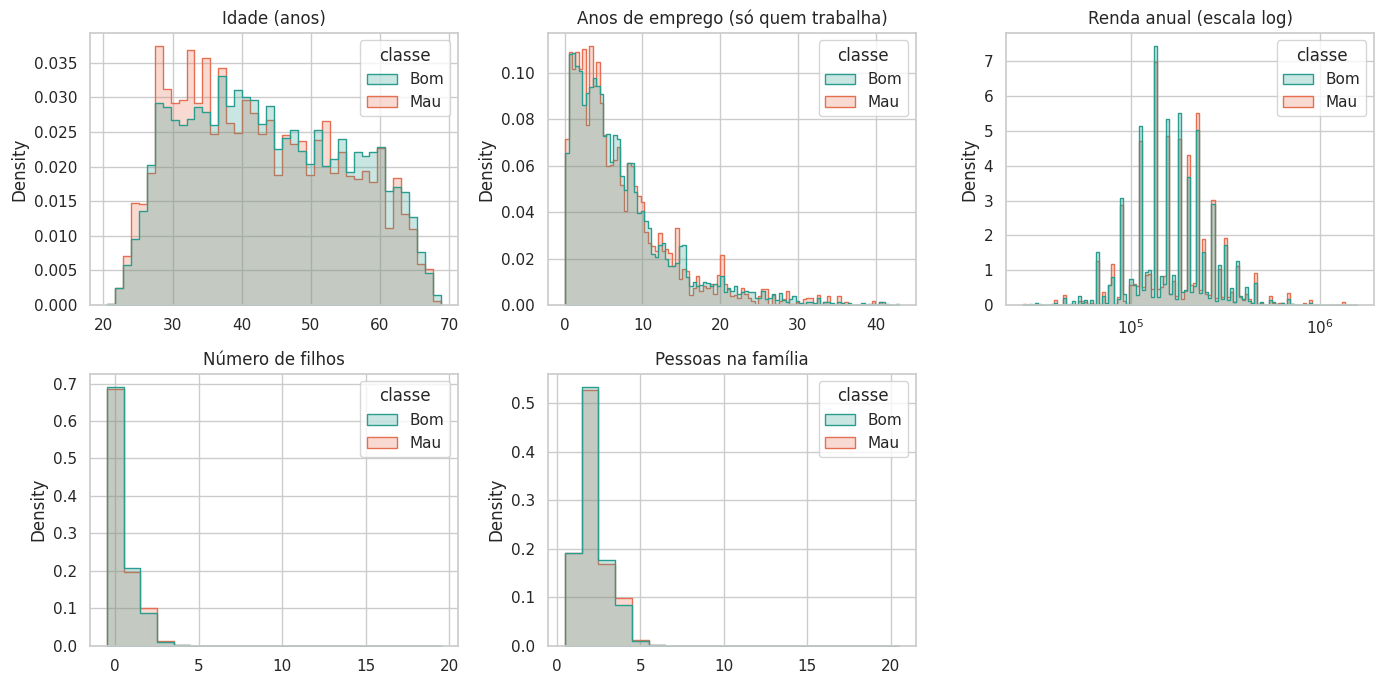

In [5]:
b = base.copy()
b["AGE_YEARS"] = -b.DAYS_BIRTH / 365.25
b["SEM_EMPREGO"] = (b.DAYS_EMPLOYED == 365243).astype(int)
b["YEARS_EMPLOYED"] = np.where(b.SEM_EMPREGO == 1, np.nan, -b.DAYS_EMPLOYED / 365.25)
b["classe"] = b.TARGET.map({0: "Bom", 1: "Mau"})

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, (col, titulo) in zip(axes.ravel(), [("AGE_YEARS", "Idade (anos)"), ("YEARS_EMPLOYED", "Anos de emprego (só quem trabalha)"),
                                          ("AMT_INCOME_TOTAL", "Renda anual (escala log)"), ("CNT_CHILDREN", "Número de filhos"),
                                          ("CNT_FAM_MEMBERS", "Pessoas na família")]):
    sns.histplot(data=b, x=col, hue="classe", stat="density", common_norm=False, element="step", hue_order=["Bom", "Mau"], palette=["#2a9d8f", "#e76f51"],
                 log_scale=(col == "AMT_INCOME_TOTAL"), discrete=col.startswith("CNT"), ax=ax)
    ax.set_title(titulo); ax.set_xlabel("")
axes.ravel()[-1].axis("off"); plt.tight_layout(); plt.show()

print(b[["AGE_YEARS", "YEARS_EMPLOYED", "AMT_INCOME_TOTAL", "CNT_CHILDREN", "CNT_FAM_MEMBERS"]].describe().round(1).T[["mean", "50%", "min", "max"]])
print(f"\nSem emprego/aposentados: {b.SEM_EMPREGO.mean():.1%} | Sem filhos: {(b.CNT_CHILDREN == 0).mean():.1%}")

**Leitura:**
- **Idade:** clientes de 20 a 69 anos, com mediana de ~43 anos (distribuição espalhada, sem concentração extrema).
- **Anos de emprego:** mediana de ~5,5 anos no emprego atual, com cauda de até 43 anos. 16,8% não têm emprego (aposentados/desempregados) e ficam fora desse gráfico.
- **Renda:** muito concentrada em valores baixos/médios (mediana de 157,5 mil por ano), com poucos casos muito altos (por isso usamos escala logarítmica).
- **Filhos e família:** a maioria não tem filhos (69%) e as famílias são pequenas.
- **O mais importante:** em todos os gráficos, a curva dos **bons (verde)** e a dos **maus (laranja) quase se sobrepõem**. Isso adianta o que veremos depois:
  nenhuma característica isolada separa bem bons de maus pagadores.

## 5. Outliers (valores extremos)

Filhos > 5: 26 | Família > 7: 26


,variável,"limite (Q3 + 1,5·IQR)",acima do limite,% das linhas,p99,máximo
0,AMT_INCOME_TOTAL,380250.0,19108,4.4,540000.0,6750000.0
1,CNT_CHILDREN,2.5,6075,1.4,3.0,19.0
2,CNT_FAM_MEMBERS,4.5,5690,1.3,5.0,20.0


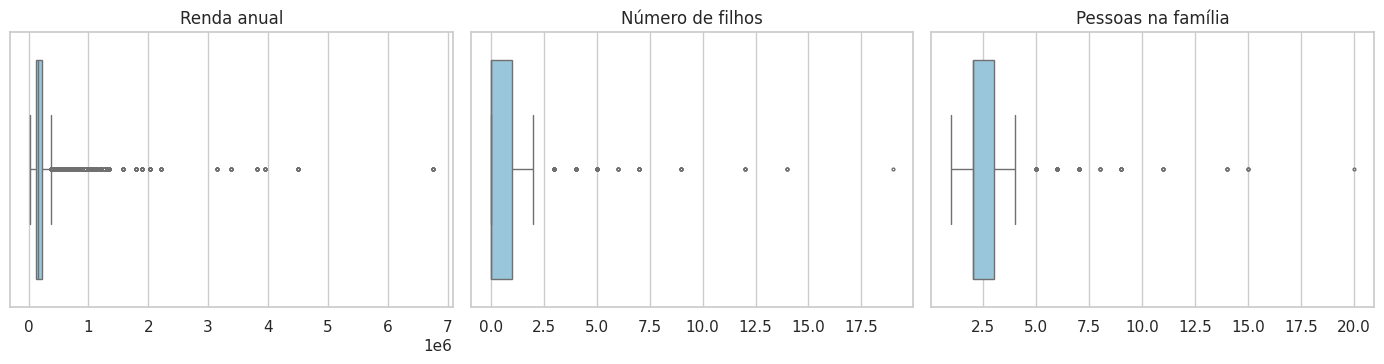

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (col, titulo) in zip(axes, [("AMT_INCOME_TOTAL", "Renda anual"), ("CNT_CHILDREN", "Número de filhos"), ("CNT_FAM_MEMBERS", "Pessoas na família")]):
    sns.boxplot(x=app[col], ax=ax, color="#8ecae6", fliersize=2); ax.set_title(titulo); ax.set_xlabel("")
plt.tight_layout(); plt.show()

linhas = []
for col in ["AMT_INCOME_TOTAL", "CNT_CHILDREN", "CNT_FAM_MEMBERS"]:
    q1, q3 = app[col].quantile([.25, .75]); lim = q3 + 1.5 * (q3 - q1)
    linhas.append({"variável": col, "limite (Q3 + 1,5·IQR)": round(lim, 1), "acima do limite": int((app[col] > lim).sum()),
                   "% das linhas": round((app[col] > lim).mean() * 100, 1), "p99": app[col].quantile(.99), "máximo": app[col].max()})
display(pd.DataFrame(linhas))
print("Filhos > 5:", int((app.CNT_CHILDREN > 5).sum()), "| Família > 7:", int((app.CNT_FAM_MEMBERS > 7).sum()))

**Leitura:** existem valores extremos nas três variáveis.
- **Renda:** no cadastro completo, 99% das pessoas ganham até ~540 mil/ano, mas há casos de até 6,75 milhões. Cerca de 4% das linhas ficam acima do limite estatístico de outlier. Esses casos puxam a média e atrapalham modelos sensíveis à escala.
- **Filhos e família:** cerca de 1% a 1,5% das linhas ficam acima do limite, com registros de até 19 filhos e 20 pessoas na família, bem acima do normal.

**Decisão de tratamento (feita no notebook 02):** não removemos esses clientes (perderíamos informação), mas limitamos as caudas (filhos ≤ 5, família ≤ 7) e usamos o **logaritmo da renda**, que reduz o peso dos valores muito altos.

## 6. Correlações

Correlação de cada variável com TARGET (ordenada):
AGE_YEARS         -0.029
FLAG_OWN_REALTY   -0.028
SEM_EMPREGO       -0.022
IS_MALE            0.021
FLAG_EMAIL         0.020
LOG_INCOME         0.019
CNT_CHILDREN       0.012
FLAG_OWN_CAR      -0.011
CNT_FAM_MEMBERS    0.009
FLAG_PHONE        -0.006
YEARS_EMPLOYED     0.005
FLAG_WORK_PHONE   -0.000


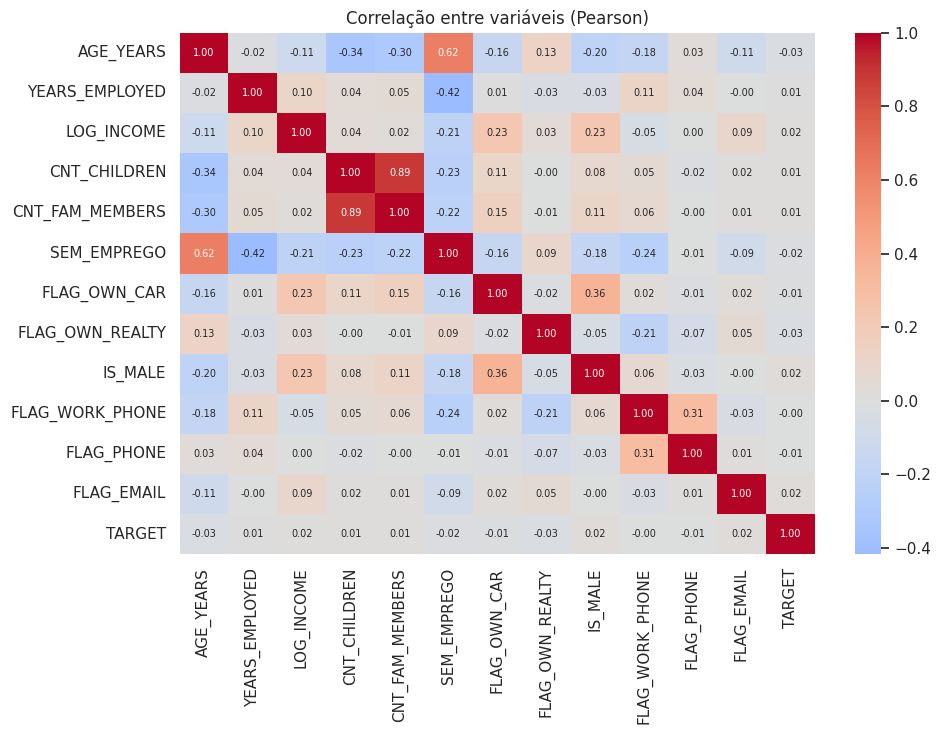

In [7]:
c = b.copy()
c["YEARS_EMPLOYED"] = c["YEARS_EMPLOYED"].fillna(0)
c["LOG_INCOME"] = np.log1p(c.AMT_INCOME_TOTAL)
c["FLAG_OWN_CAR"] = (c.FLAG_OWN_CAR == "Y").astype(int); c["FLAG_OWN_REALTY"] = (c.FLAG_OWN_REALTY == "Y").astype(int)
c["IS_MALE"] = (c.CODE_GENDER == "M").astype(int)
cols = ["AGE_YEARS", "YEARS_EMPLOYED", "LOG_INCOME", "CNT_CHILDREN", "CNT_FAM_MEMBERS", "SEM_EMPREGO", "FLAG_OWN_CAR", "FLAG_OWN_REALTY", "IS_MALE", "FLAG_WORK_PHONE", "FLAG_PHONE", "FLAG_EMAIL", "TARGET"]
corr = c[cols].corr()
fig, ax = plt.subplots(figsize=(10, 7.5))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax); ax.set_title("Correlação entre variáveis (Pearson)")
plt.tight_layout(); plt.show()
print("Correlação de cada variável com TARGET (ordenada):"); print(corr.TARGET.drop("TARGET").round(3).sort_values(key=abs, ascending=False).to_string())

**Leitura:**
- **Número de filhos × pessoas na família** têm correlação muito alta (~0,9): carregam praticamente a mesma informação.
- **Idade × sem emprego (aposentado)** (~0,6): faz sentido, aposentados são mais velhos.
- **Nenhuma variável tem correlação relevante com ser mau pagador** (todas abaixo de 0,05 em valor absoluto). Isso é um primeiro sinal de que será difícil prever.

## 7. Bons e maus pagadores: quem tem mais risco?
Taxa de maus pagadores em cada grupo (linha vermelha = média geral, 11,8%).

,% maus,clientes
faixa de idade,,
"(20, 30]",13.4,4960
"(30, 40]",12.4,10424
"(40, 50]",11.2,9319
"(50, 60]",11.2,7964
"(60, 70]",10.6,3790


,% maus,clientes
imóvel próprio,,
N,13.1,11951
Y,11.1,24506


,% maus,clientes
carro próprio,,
N,12.0,22614
Y,11.3,13843


,% maus,clientes
gênero,,
F,11.3,24430
M,12.7,12027


,% maus,clientes
faixa de renda,,
25% mais baixa,11.3,9393
média-baixa,11.3,9170
média-alta,12.0,10125
25% mais alta,12.6,7769


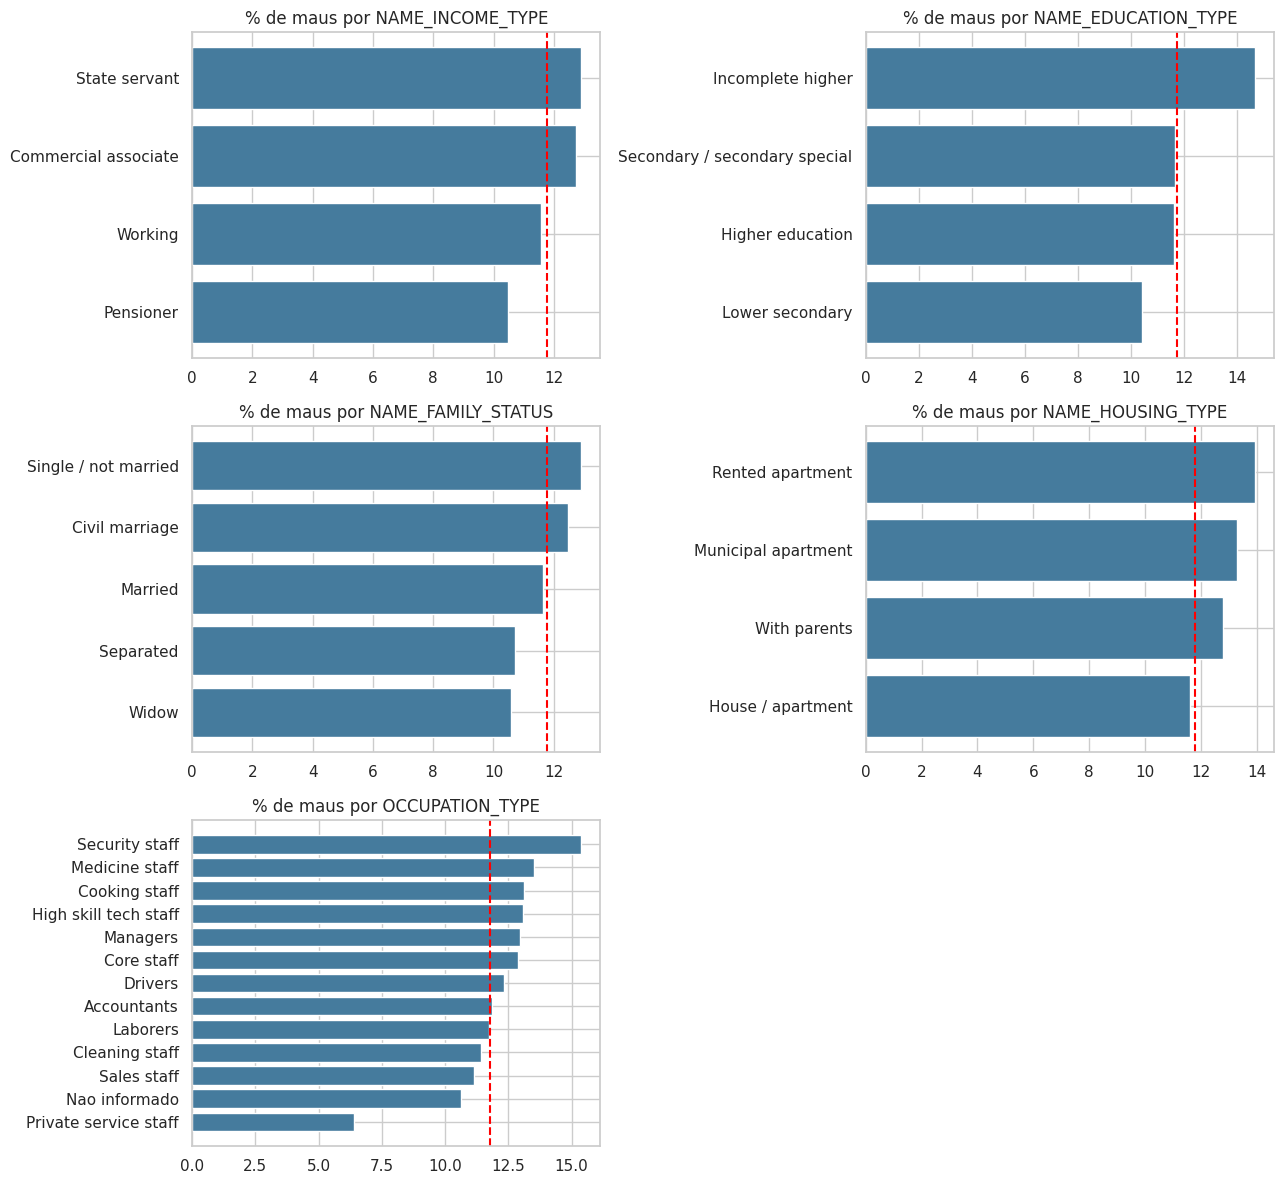

In [8]:
cat_cols = ["NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE", "NAME_FAMILY_STATUS", "NAME_HOUSING_TYPE", "OCCUPATION_TYPE"]
b["OCCUPATION_TYPE"] = b.OCCUPATION_TYPE.fillna("Nao informado")
fig, axes = plt.subplots(3, 2, figsize=(13, 12))
for ax, col in zip(axes.ravel(), cat_cols):
    r = b.groupby(col).TARGET.agg(["mean", "size"]).query("size >= 300").sort_values("mean")
    ax.barh(r.index, r["mean"] * 100, color="#457b9d"); ax.axvline(b.TARGET.mean() * 100, color="red", ls="--"); ax.set_title(f"% de maus por {col}")
axes.ravel()[-1].axis("off"); plt.tight_layout(); plt.show()

def taxa(serie, nome):
    t = b.groupby(serie, observed=True).TARGET.agg(["mean", "size"]); t["mean"] = (t["mean"] * 100).round(1); t.columns = ["% maus", "clientes"]; t.index.name = nome; return t
display(taxa(pd.cut(b.AGE_YEARS, [20, 30, 40, 50, 60, 70]), "faixa de idade"))
display(taxa(b.FLAG_OWN_REALTY, "imóvel próprio"))
display(taxa(b.FLAG_OWN_CAR, "carro próprio"))
display(taxa(b.CODE_GENDER, "gênero"))
display(taxa(pd.qcut(b.AMT_INCOME_TOTAL, 4, labels=["25% mais baixa", "média-baixa", "média-alta", "25% mais alta"]), "faixa de renda"))

**Leitura (diferenças pequenas, mas consistentes):**
- **Idade:** quanto mais jovem, maior a taxa de maus: 13,4% entre 20–30 anos contra 10,6% entre 60–70.
- **Gênero:** 12,7% de maus entre homens e 11,3% entre mulheres.
- **Imóvel próprio:** 11,1% de maus entre quem tem imóvel, contra 13,1% entre quem não tem. Carro próprio mostra a mesma direção, mas mais fraca (11,3% × 12,0%).
- **Renda:** ao contrário do que se espera, a faixa de renda mais alta tem *um pouco mais* de maus (12,6%) que a mais baixa (11,3%). A renda não protege contra atraso nesta base.
- **Perfis:** quem tem ensino superior incompleto (14,7%), moradores de apartamento alugado (13,9%) e solteiros (12,9%) estão acima da média; aposentados (10,5%), viúvos e separados (~10,6%) estão abaixo.
- Todas as diferenças ficam entre 1 e 3 pontos percentuais. São sinais fracos.

## 8. As diferenças são reais ou acaso? Testes estatísticos

In [9]:
linhas = []
num = {"AGE_YEARS": b.AGE_YEARS, "YEARS_EMPLOYED": c.YEARS_EMPLOYED, "LOG_INCOME": c.LOG_INCOME, "CNT_CHILDREN": b.CNT_CHILDREN, "CNT_FAM_MEMBERS": b.CNT_FAM_MEMBERS}
for nome, s in num.items():
    p = stats.mannwhitneyu(s[b.TARGET == 0], s[b.TARGET == 1]).pvalue
    linhas.append({"variável": nome, "teste": "Mann-Whitney", "p-valor": p, "tamanho do efeito (V de Cramér)": np.nan})
cats = {"FLAG_OWN_REALTY": b.FLAG_OWN_REALTY, "FLAG_OWN_CAR": b.FLAG_OWN_CAR, "CODE_GENDER": b.CODE_GENDER, "SEM_EMPREGO": b.SEM_EMPREGO,
        "FLAG_EMAIL": b.FLAG_EMAIL, "FLAG_PHONE": b.FLAG_PHONE, "FLAG_WORK_PHONE": b.FLAG_WORK_PHONE, **{k: b[k] for k in cat_cols}}
for nome, s in cats.items():
    tab = pd.crosstab(s, b.TARGET); chi2, p, *_ = stats.chi2_contingency(tab)
    v = (chi2 / (len(b) * (min(tab.shape) - 1))) ** .5
    linhas.append({"variável": nome, "teste": "Qui-quadrado", "p-valor": p, "tamanho do efeito (V de Cramér)": round(v, 4)})
t = pd.DataFrame(linhas).sort_values("p-valor"); t["significativo (p<0,05)"] = np.where(t["p-valor"] < 0.05, "sim", "não")
display(t.round(5))

,variável,teste,p-valor,tamanho do efeito (V de Cramér),"significativo (p<0,05)"
0,AGE_YEARS,Mann-Whitney,0.00000,NaN,sim
5,FLAG_OWN_REALTY,Qui-quadrado,0.00000,0.0279,sim
16,OCCUPATION_TYPE,Qui-quadrado,0.00000,0.0417,sim
8,SEM_EMPREGO,Qui-quadrado,0.00004,0.0215,sim
7,CODE_GENDER,Qui-quadrado,0.00005,0.0212,sim
9,FLAG_EMAIL,Qui-quadrado,0.00020,0.0195,sim
12,NAME_INCOME_TYPE,Qui-quadrado,0.00022,0.0244,sim
2,LOG_INCOME,Mann-Whitney,0.00173,NaN,sim
13,NAME_EDUCATION_TYPE,Qui-quadrado,0.00340,0.0208,sim
14,NAME_FAMILY_STATUS,Qui-quadrado,0.01601,0.0183,sim


**Leitura:** o teste de hipótese pergunta "essa diferença pode ser acaso?". Idade, imóvel próprio, ocupação, gênero e e-mail têm diferença **estatisticamente significativa** (p < 0,05).
Mas o **tamanho do efeito** (V de Cramér) é minúsculo, sempre abaixo de 0,05, em uma escala que vai até 1. Com 36 mil clientes, até diferenças pequenas viram "significativas".
Traduzindo: **as diferenças existem, mas são pequenas demais para identificar sozinhas um mau pagador.**

## 9. Perfis repetidos

In [10]:
feat = [c_ for c_ in base.columns if c_ not in ("ID", "TARGET")]
unicos = base.drop_duplicates(feat)
print(f"Clientes: {len(base):,} | perfis únicos (mesmas características): {len(unicos):,}".replace(",", "."))
print(f"Linhas que repetem um perfil já existente: {1 - len(unicos)/len(base):.1%}")
print(f"Clientes que pertencem a um perfil que aparece mais de uma vez: {base.duplicated(feat, keep=False).mean():.1%}")

Clientes: 36.457 | perfis únicos (mesmas características): 9.728
Linhas que repetem um perfil já existente: 73.3%
Clientes que pertencem a um perfil que aparece mais de uma vez: 91.4%


**Leitura (achado importante):** os 36.457 clientes correspondem a apenas **9.728 perfis únicos** (9.727 depois do tratamento de outliers do notebook 02). Muitos clientes têm exatamente as mesmas características cadastrais. Se esses "gêmeos" caírem um no treino e outro no teste, o modelo só precisa **decorar** o perfil,
e o resultado parece bom sem ser. No notebook 03 isso é evitado com uma divisão **agrupada por perfil**, e no notebook 04 medimos quanto isso importa.